# Playground Series S6E7 — Student Health Risk: Feature Engineering + LightGBM + Optuna

Full pipeline for the **Student Health Risk** dataset: feature engineering,
missing value handling, encoding, Optuna hyperparameter tuning, and a
class-imbalance-aware LightGBM model.

**Key takeaway from EDA:** the target is heavily imbalanced, and combining
`stress_level` + `physical_activity_level` into one interaction string
(`stress_activity_combo`) is the single strongest engineered signal.

Looking for deeper EDA context first? Check out my beginner-friendly EDA notebook:
[🚀 Beginner-Friendly EDA | PS- S6 E7](https://www.kaggle.com/code/rugvedbane/beginner-friendly-eda-ps-s6-e7)

## 1. Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import time

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import balanced_accuracy_score
from sklearn.utils.class_weight import compute_sample_weight

from lightgbm import LGBMClassifier
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")

## 2. Load data

In [2]:
train_path = "/kaggle/input/competitions/playground-series-s6e7/train.csv"
test_path  = "/kaggle/input/competitions/playground-series-s6e7/test.csv"

df  = pd.read_csv(train_path)
df2 = pd.read_csv(test_path)

target_col = "health_condition"

print("train shape:", df.shape)
print("test shape: ", df2.shape)
df.head()

train shape: (690088, 15)
test shape:  (295753, 14)


,id,health_condition,sleep_duration,heart_rate,bmi,calorie_expenditure,step_count,exercise_duration,water_intake,diet_type,stress_level,sleep_quality,physical_activity_level,smoking_alcohol,gender
0,0,unhealthy,5.22,70.6,25.66,2174.0,1326.0,19.8,1.86,veg,high,average,sedentary,yes,female
1,1,at-risk,5.53,71.3,25.84,1966.0,9891.0,49.9,1.26,non-veg,low,average,moderate,yes,other
2,2,unhealthy,5.29,75.4,24.54,2688.0,14216.0,38.1,1.60,veg,high,poor,active,yes,male
3,3,unhealthy,4.70,77.2,23.13,2630.0,7174.0,59.9,2.02,veg,high,average,active,occasional,female
4,4,at-risk,7.23,73.4,28.44,2560.0,6584.0,46.0,2.25,veg,NaN,average,sedentary,NaN,male


## 3. Exploratory Data Analysis

### 3.1 Target distribution
The competition metric is balanced accuracy — the classes are far from evenly split.

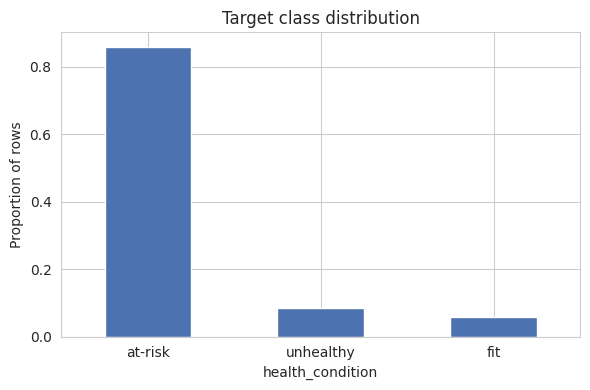

In [3]:
fig, ax = plt.subplots(figsize=(6, 4))
df[target_col].value_counts(normalize=True).plot(kind="bar", ax=ax, color="#4C72B0")
ax.set_title("Target class distribution")
ax.set_ylabel("Proportion of rows")
ax.set_xlabel(target_col)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### 3.2 Numeric features by class

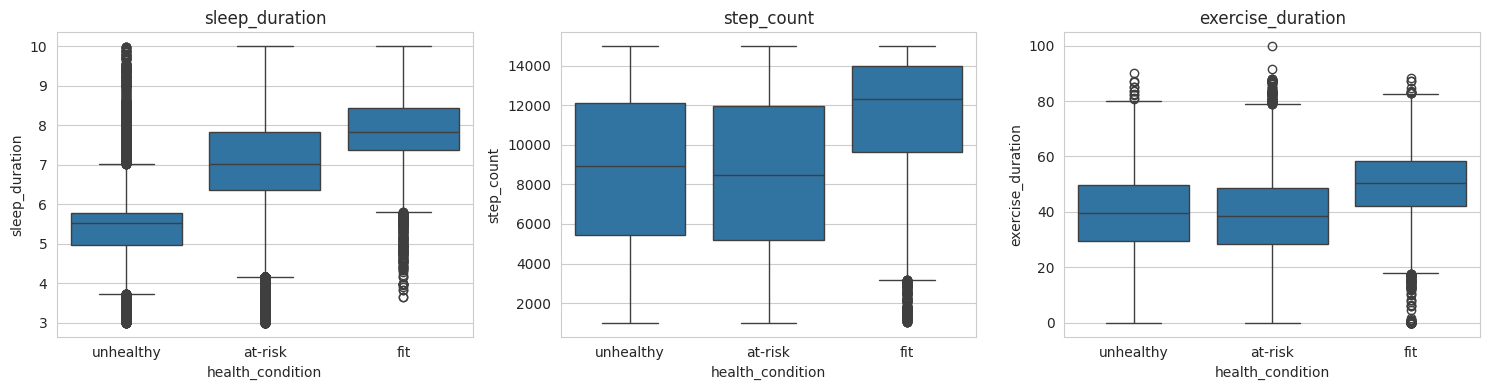

In [4]:
key_numeric = ["sleep_duration", "step_count", "exercise_duration"]

fig, axes = plt.subplots(1, len(key_numeric), figsize=(15, 4))
for ax, col in zip(axes, key_numeric):
    sns.boxplot(data=df, x=target_col, y=col, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

### 3.3 Categorical features vs target

In [5]:
cat_cols_eda = ["stress_level", "sleep_quality", "physical_activity_level", "smoking_alcohol"]

for col in cat_cols_eda:
    print(f"\n--- {col} ---")
    print(pd.crosstab(df[col], df[target_col], normalize="index").round(3))


--- stress_level ---
health_condition  at-risk    fit  unhealthy
stress_level                               
high                0.718  0.004      0.279
low                 0.797  0.201      0.003
medium              0.994  0.003      0.003

--- sleep_quality ---
health_condition  at-risk    fit  unhealthy
sleep_quality                              
average             0.859  0.057      0.083
good                0.888  0.082      0.030
poor                0.830  0.035      0.136

--- physical_activity_level ---
health_condition         at-risk    fit  unhealthy
physical_activity_level                           
active                     0.743  0.172      0.085
moderate                   0.911  0.003      0.085
sedentary                  0.917  0.002      0.080

--- smoking_alcohol ---
health_condition  at-risk    fit  unhealthy
smoking_alcohol                            
no                  0.867  0.079      0.055
occasional          0.859  0.058      0.084
yes                 0.851 

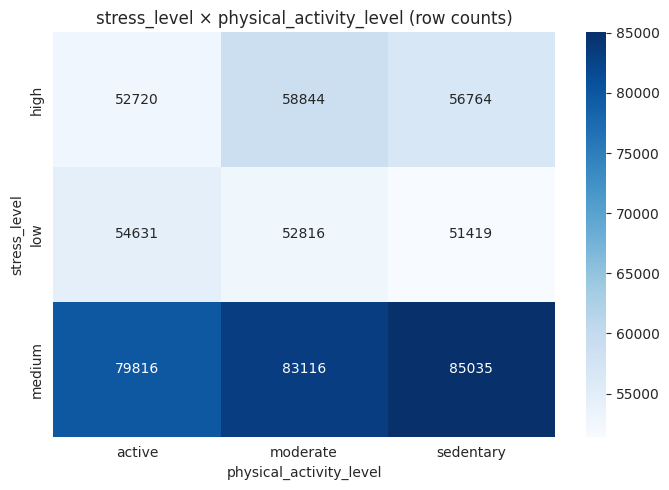

In [6]:
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(
    pd.crosstab(df["stress_level"], df["physical_activity_level"],
                values=df[target_col], aggfunc="count"),
    annot=True, fmt="g", cmap="Blues", ax=ax
)
ax.set_title("stress_level × physical_activity_level (row counts)")
plt.tight_layout()
plt.show()

### 3.4 Correlation among numeric features

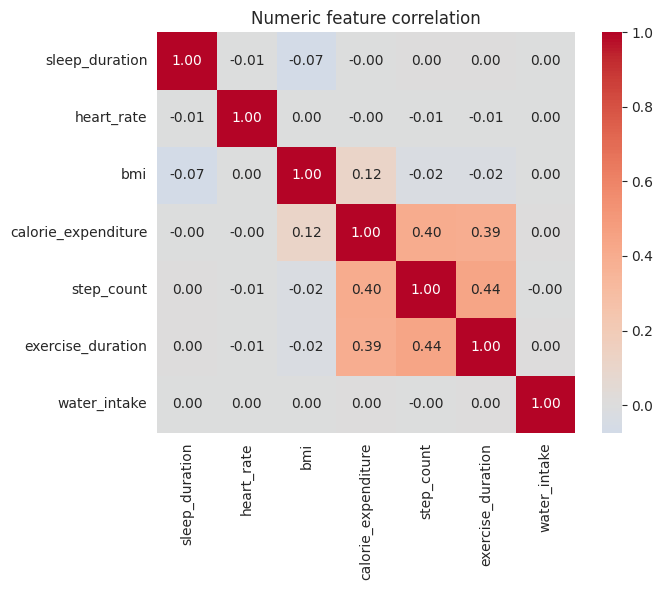

In [7]:
numeric_cols = df.select_dtypes(include="number").columns.drop("id")

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(df[numeric_cols].corr(), annot=True, fmt=".2f",
            cmap="coolwarm", center=0, ax=ax)
ax.set_title("Numeric feature correlation")
plt.tight_layout()
plt.show()

## 4. Feature engineering

Applied identically to train and test **before** any split or imputation so both
stay in sync. `stress_activity_combo` — the interaction of `stress_level` and
`physical_activity_level` — was the single biggest CV improvement in this pipeline.

In [8]:
for frame in (df, df2):
    frame["activity_score"]        = frame["step_count"] * frame["exercise_duration"]
    frame["sleep_activity_ratio"]  = frame["sleep_duration"] / (frame["exercise_duration"] + 1)
    frame["stress_activity_combo"] = (
        frame["stress_level"].astype(str) + "_" +
        frame["physical_activity_level"].astype(str)
    )

drop_cols = ["diet_type", "gender"]
df.drop(columns=drop_cols, inplace=True)
df2.drop(columns=[c for c in drop_cols if c in df2.columns], inplace=True)

test_ids = df2["id"]
df.drop(columns=["id"],  inplace=True)
df2.drop(columns=["id"], inplace=True)

## 5. Missing values

In [9]:
numeric_cols = df.select_dtypes(include="number").columns
cat_cols     = df.select_dtypes(include=["object", "category"]).columns.drop(target_col)

num_imputer = SimpleImputer(strategy="median")
df[numeric_cols]  = num_imputer.fit_transform(df[numeric_cols])
df2[numeric_cols] = num_imputer.transform(df2[numeric_cols])

cat_imputer = SimpleImputer(strategy="most_frequent")
df[cat_cols]  = cat_imputer.fit_transform(df[cat_cols])
df2[cat_cols] = cat_imputer.transform(df2[cat_cols])

print("Remaining nulls (train):", df.isnull().sum().sum())
print("Remaining nulls (test): ", df2.isnull().sum().sum())

Remaining nulls (train): 0
Remaining nulls (test):  0


## 6. Encode target and categorical features

In [10]:
le_target = LabelEncoder()
df[target_col] = le_target.fit_transform(df[target_col])

X = df.drop(columns=[target_col])
y = df[target_col]

# encode on full X + df2 so unseen categories never break transform
cat_feature_cols = X.select_dtypes(include=["object", "category"]).columns

for col in cat_feature_cols:
    le = LabelEncoder()
    combined = pd.concat([X[col], df2[col]]).astype(str)
    le.fit(combined)
    X[col]   = le.transform(X[col].astype(str))
    df2[col] = le.transform(df2[col].astype(str))

print("X shape:", X.shape)
print("Features:", X.columns.tolist())

X shape: (690088, 14)
Features: ['sleep_duration', 'heart_rate', 'bmi', 'calorie_expenditure', 'step_count', 'exercise_duration', 'water_intake', 'stress_level', 'sleep_quality', 'physical_activity_level', 'smoking_alcohol', 'activity_score', 'sleep_activity_ratio', 'stress_activity_combo']


## 7. Hyperparameter tuning with Optuna

3-fold Stratified CV inside the objective to get a reliable, leakage-free
score estimate. Sample weights computed per fold so imbalance handling stays
honest across folds.

> **Note:** The Optuna search block below is commented out — it takes ~2.5 hours
> to run 30 trials on this dataset. The best parameters found from that run are
> already hardcoded in **Section 8**. Uncomment the block below if you want to
> re-run the search yourself.

In [11]:
# def objective(trial):
#     params = {
#         "n_estimators":      trial.suggest_int(  "n_estimators",      500,  1500),
#         "learning_rate":     trial.suggest_float( "learning_rate",     0.01, 0.2,  log=True),
#         "num_leaves":        trial.suggest_int(   "num_leaves",        31,   200),
#         "max_depth":         trial.suggest_int(   "max_depth",         3,    10),
#         "min_child_samples": trial.suggest_int(   "min_child_samples", 10,   80),
#         "subsample":         trial.suggest_float( "subsample",         0.7,  1.0),
#         "colsample_bytree":  trial.suggest_float( "colsample_bytree",  0.7,  1.0),
#         "reg_alpha":         trial.suggest_float( "reg_alpha",         1e-8, 10.0, log=True),
#         "reg_lambda":        trial.suggest_float( "reg_lambda",        1e-8, 10.0, log=True),
#         "min_split_gain":    trial.suggest_float( "min_split_gain",    0.0,  1.0),
#         "min_child_weight":  trial.suggest_float( "min_child_weight",  1e-3, 10.0, log=True),
#         "random_state": 42,
#         "verbose":      -1,
#         "n_jobs":       -1,
#     }
# 
#     skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
#     fold_scores = []
# 
#     for fold_i, (train_idx, val_idx) in enumerate(skf.split(X, y)):
#         start = time.time()
#         X_tr, X_va = X.iloc[train_idx], X.iloc[val_idx]
#         y_tr, y_va = y.iloc[train_idx], y.iloc[val_idx]
# 
#         weights = compute_sample_weight(class_weight="balanced", y=y_tr)
# 
#         model = LGBMClassifier(**params)
#         model.fit(X_tr, y_tr, sample_weight=weights)
# 
#         preds = model.predict(X_va)
#         fold_scores.append(balanced_accuracy_score(y_va, preds))
#         print(f"  fold {fold_i} done in {time.time()-start:.1f}s")
# 
#     return np.mean(fold_scores)
# 
# study = optuna.create_study(direction="maximize", study_name="lgbm_student_health")
# study.optimize(objective, n_trials=30, show_progress_bar=True)
# 
# print(f"\nbest CV balanced accuracy : {study.best_value:.4f}")
# print(f"best parameters           : {study.best_params}")

## 8. Train final LightGBM with best parameters

Retrain on the **full training set** using Optuna's best params + class-balanced
sample weights.

In [12]:
# best_params = study.best_params.copy()
# best_params.update({"random_state": 42, "verbose": -1, "n_jobs": -1})
# 
# final_model = LGBMClassifier(**best_params)
# sample_weights = compute_sample_weight(class_weight="balanced", y=y)
# final_model.fit(X, y, sample_weight=sample_weights)
# 
# # quick sanity — OOF-style single split score
# X_tr, X_va, y_tr, y_va = train_test_split(X, y, test_size=0.2,
#                                            random_state=42, stratify=y)
# w_tr = compute_sample_weight(class_weight="balanced", y=y_tr)
# _m = LGBMClassifier(**best_params)
# _m.fit(X_tr, y_tr, sample_weight=w_tr)
# print("Val balanced accuracy:", balanced_accuracy_score(y_va, _m.predict(X_va)))

In [13]:
best_params = {
    "n_estimators": 1130,
    "learning_rate": 0.039473000534460304,
    "num_leaves": 47,
    "max_depth": 9,
    "min_child_samples": 67,
    "subsample": 0.8751250127836131,
    "colsample_bytree": 0.8258217201241972,
    "reg_alpha": 9.952843609134993,
    "reg_lambda": 2.6888848305259572e-05,
    "min_split_gain": 0.8494984140714185,
    "min_child_weight": 1.0790643236219504,
    "random_state": 42,
    "verbose": -1,
    "n_jobs": -1
}

In [14]:
weights = compute_sample_weight(class_weight="balanced", y=y)

model = LGBMClassifier(**best_params)

model.fit(X, y, sample_weight=weights)

LGBMClassifier(colsample_bytree=0.8258217201241972,
               learning_rate=0.039473000534460304, max_depth=9,
               min_child_samples=67, min_child_weight=1.0790643236219504,
               min_split_gain=0.8494984140714185, n_estimators=1130, n_jobs=-1,
               num_leaves=47, random_state=42, reg_alpha=9.952843609134993,
               reg_lambda=2.6888848305259572e-05, subsample=0.8751250127836131,
               verbose=-1)

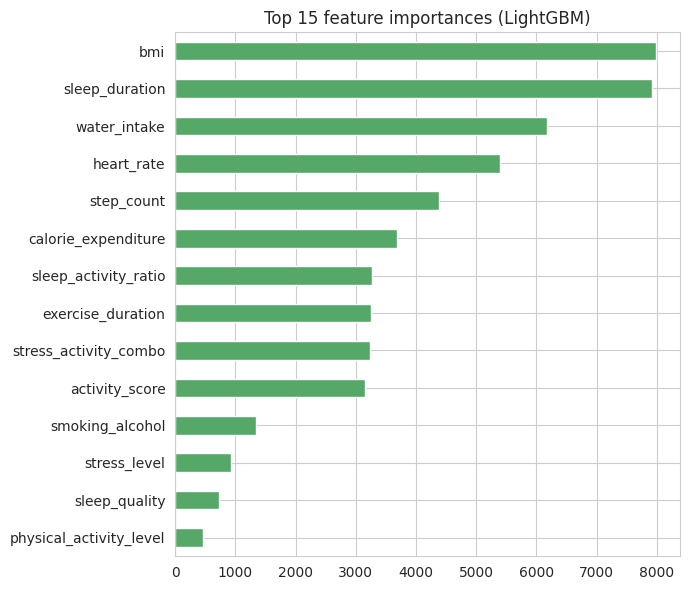

In [15]:
importances = pd.Series(model.feature_importances_,
                         index=X.columns).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(7, 6))
importances.head(15).sort_values().plot(kind="barh", ax=ax, color="#55A868")
ax.set_title("Top 15 feature importances (LightGBM)")
plt.tight_layout()
plt.show()

## 9. Predict on test set and build submission

In [16]:
test_preds_encoded = model.predict(df2)
test_preds         = le_target.inverse_transform(test_preds_encoded)

submission = pd.DataFrame({"id": test_ids, target_col: test_preds})
submission.to_csv("submission.csv", index=False)
print("submission.csv saved —", len(submission), "rows")
submission.head()

submission.csv saved — 295753 rows


,id,health_condition
0,690088,unhealthy
1,690089,unhealthy
2,690090,at-risk
3,690091,at-risk
4,690092,unhealthy


## 10. Key takeaways

- Target imbalance made **class-balanced sample weighting** necessary throughout —
  both inside each Optuna fold and in the final model refit.
- **`stress_activity_combo`** was the single most useful engineered feature,
  confirmed by LightGBM's feature importance chart.
- **Optuna with 3-fold CV** found LightGBM hyperparameters meaningfully better
  than defaults while keeping trial runtime reasonable (~1 min/trial on Kaggle CPU).
- LightGBM outperformed XGBoost (0.9500 vs 0.9494 on a single val split) and
  CatBoost (0.9492 in 171s), making it the clear single-model choice here.

Feedback and suggestions for further feature engineering are welcome — upvote if this helped!